### Quench dynamics with emu_cheb (port of the emu-sv tutorial) in presence of some noise channels

In this tutorial, we will introduce our EMU-SV master equation solver of a quench sequence in presence of effective noise channels or jump operators.  For more information related to effective noise, please take a look at the following pulser effective noise [documentation](https://pulser.readthedocs.io/en/stable/tutorials/effective_noise.html). This tutorial is based on `Quench dynamics` tutorial. 

**emu_cheb port.** Same tutorial, run by `emu_cheb.ChebBackend` (exact Chebyshev engines of `emu_cheb.solvers`, see `emu_cheb/README.md`) instead of `emu_sv.SVBackend`: only the backend and config classes change. emu-sv solves the Lindblad master equation (density matrix); emu_cheb averages `n_traj` exact quantum trajectories (emu-mps' noise model), so its occupations carry a statistical error ~ 1/sqrt(n_traj), compared below (z = difference / standard error; at the earliest times, when almost no trajectory has jumped yet, the per-trajectory spread underestimates the error and z is unreliable with few trajectories).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace

#pulser imports
from pulser.devices import AnalogDevice
from pulser import Sequence, Register, Pulse
from pulser.channels import Rydberg
from pulser.noise_model import NoiseModel # effective noise or jump operators

#emulators imports
import emu_cheb
import emu_sv  # reference only


In [2]:
# define the register arregement function and the device for the quench
def chain_coordinates(N,R1,R2):
    """Generate the coordinates of a chain of points arranged in two parallel 
    lines."""
    coords = [(-R2/2,i*R1-(N-1)/2*R1) for i in range(N)]
    coords = coords + [(R2/2,i*R1-(N-1)/2*R1) for i in range(N)]
    return coords


# device settings
VD = AnalogDevice.to_virtual()
VD = replace(
    VD, 
    max_atom_num=50,
    max_radial_distance=38,
    max_sequence_duration=None,
    channel_objects=(
        Rydberg.Global(48.69468613064179, 12.566370614359172),
    ))

The registers will be arranged in two parallel lines, each containing $N$ atoms, as generated by the function `chain_coordinates`. The atoms will be vertically separated by $R_1$ and horizontally by $R_2$ . The $U_i$ terms represent the interaction energies between pairs of atoms at various distances. For instance,  $U_1$ represents the interaction energy between nearest neighbors along the same line, separated by a distance $R_1$. $U_2$ is the interaction energy between atoms across the two parallel lines, separated by the horizontal distance $R_2$, and so on.

/Users/i.sokolov/Code/emulators/.venv/lib/python3.12/site-packages/pulser/register/register.py:58: DeprecationWarning: Usage of `int`s or any non-`str`types as `QubitId`s will be deprecated. Define your `QubitId`s as `str`s, prefer setting `prefix='q'` when using classmethods, as that will become the new default once `int` qubit IDs become invalid.
  super().__init__(qubits, **kwargs)


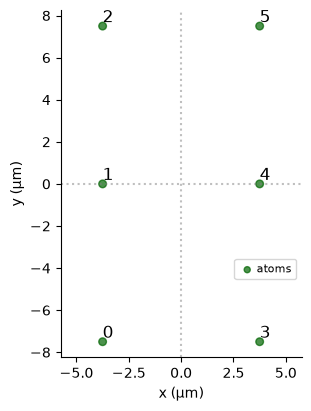

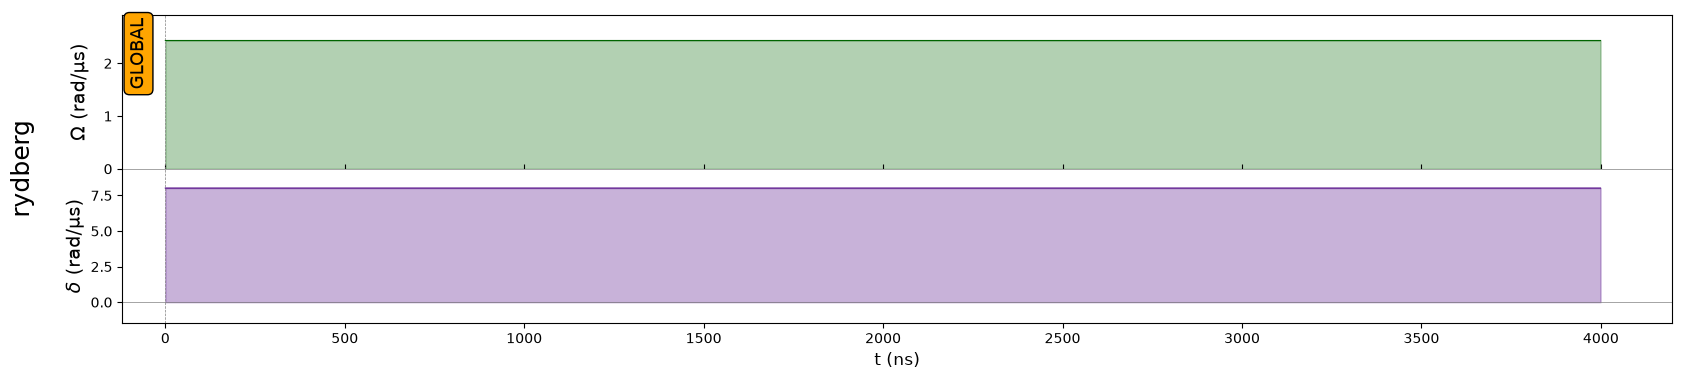

In [3]:
# Parameters for the system
N  = 3 # number of atoms in a line
R1 = 7.5 # vertical distance between atoms in a single chain
lam = 1
R2 = R1/(lam**(1/6)) # # Horizontal distance between the two parallel chains of atoms

U1 = VD.interaction_coeff/R1**6 #interaction with nearest neighbors in the same line
U2 = VD.interaction_coeff/R2**6 #interacion between atoms across two paralell lines
U3 = VD.interaction_coeff/(np.sqrt(R1**2+R2**2))**6 # interaction between diagonal neighbors
U4 = VD.interaction_coeff/(2*R1)**6 # second-nearest neighbors interaction in the same line
U5 = VD.interaction_coeff/(np.sqrt(4*R1**2+R2**2))**6 # second-nearest interaction across lines

coords_exact = chain_coordinates(N,R1,R2) # generate the coordinates of the atoms

hx = 1 
hz = 0 

t = 4000 # duration of the sequence
dt = 10.0 # time step

NN_coeff = U1/4
omega = 2*hx*NN_coeff
delta = (-2*hz*NN_coeff+U1+U2/2+U3+U4+U5) #compensate the interaction shift
T = t/1000*NN_coeff
dT = dt/1000*NN_coeff


# pulser register
qubits = dict(enumerate(coords_exact))
reg0 = Register(qubits)
reg0.draw()

#pulser sequence
seq = Sequence(reg0, VD)
seq.declare_channel("rydberg", "rydberg_global")
simple_pulse = Pulse.ConstantPulse(t, omega, delta, 0)
seq.add(simple_pulse, "rydberg")
seq.draw()


#### SVBackend, SVConfig and effective noise channels 

In order to run a noisy sequence, you need to instanciate *SVBackend*, *SVConfig* and pass the pulser `NoiseModel` instance to SVConfig. In this case, we are going to use 2 noise channels: `depolarizing` and `dephasing` both with rates equals to 0.1. 
In principle, one just needs to declare the noise channels or jump operators with their respective rates and EMU-SV will run with the master equation solver.

In [4]:
noise_model = NoiseModel(
        depolarizing_rate=0.1,
        dephasing_rate=0.1,
    )
n_traj = 4000  # emu_cheb: quantum trajectories (pulser's default n_trajectories is 1)

In [5]:
basis = (
    "r",
    "g",
)
step = 4*int(dt)
duration = t
eval_times = [x / t for x in range(0, duration+step, step)]  # must be from 0 to 1
occupation = emu_cheb.Occupation(evaluation_times=eval_times, one_state=basis)


# emu_cheb config
config = emu_cheb.ChebConfig(
    dt=dt, observables=[occupation], noise_model=noise_model, n_trajectories=n_traj
)  # gpu=None: CUDA if available

# emu_cheb backend
sim = emu_cheb.ChebBackend(seq, config=config)
t0 = time.perf_counter()
results = sim.run()
t_cheb = time.perf_counter() - t0
print(f"emu_cheb ({sim.raw.stats['optimization']}): {t_cheb:.2f} s")

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/solvers/rydberg_cheb_fast.py:448: UserWarning: long double is float64 here: Bessel coefficients accurate to ~4e-14 and global phase to ~1e-13 only (amplitudes ~1e-13)
  bessel = _bessel(alphas, rho)


emu_cheb (turbo): {'trajectories': 4000, 'jumps': 12168, 'leaks': 0, 'segments': 284, 'matvecs': 6471, 'row_matvecs': 5176450, 'jump_norm_dev': 1.3322676295501878e-15, 'max_growth': 0.38135595559255026, 'batches': 1, 'lanczos_matvecs': 60, 'lanczos_rejected': 0, 'small_kernel_calls': 0, 'optimization': 'turbo', 'off_diagonal_evaluations': 0}


emu_cheb (turbo): 6.08 s


### Plot the evolution of the occupation $n_i$ of all the atoms

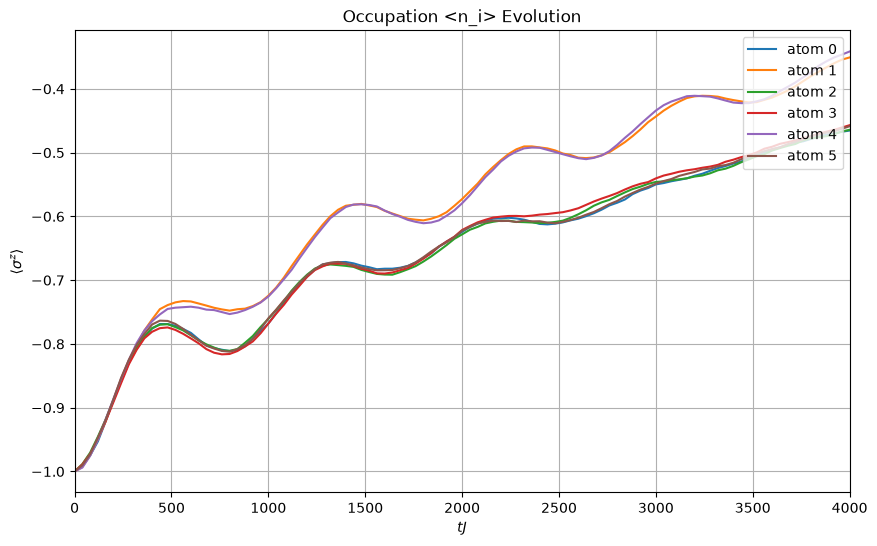

In [6]:
occupation_values = np.array(results.occupation)
times = np.arange(0, duration+step, step)

plt.figure(figsize=(10, 6)) 

for i in range(2*N):
    result_plot = occupation_values[:,i]
    plt.plot(times,2*result_plot-1,label=f'atom {i}')

plt.title('Occupation <n_i> Evolution')
plt.xlim(0,t)

plt.xlabel(r'$tJ$')
plt.ylabel(r'$\langle \sigma^z \rangle$')
plt.grid()

plt.legend(loc='upper right')
plt.show()

### Comparison with emu-sv

The same sequence with `emu_sv.SVBackend` (Lindblad master equation).

step = 1/400, RSS = 574160.896 MB, Δt = 0.010 s


step = 2/400, RSS = 574160.896 MB, Δt = 0.012 s


step = 3/400, RSS = 574160.896 MB, Δt = 0.010 s


step = 4/400, RSS = 574160.896 MB, Δt = 0.010 s


step = 5/400, RSS = 574177.280 MB, Δt = 0.010 s


...

step = 397/400, RSS = 574455.808 MB, Δt = 0.010 s


step = 398/400, RSS = 574455.808 MB, Δt = 0.010 s


step = 399/400, RSS = 574455.808 MB, Δt = 0.010 s


step = 400/400, RSS = 574455.808 MB, Δt = 0.010 s


max |<n_i> emu_cheb - emu-sv| = 0.0096 (standard error up to 0.0035; max z = 2.9)
time: emu_cheb 6.08 s, emu-sv 4.14 s (CPU unless a GPU is available)


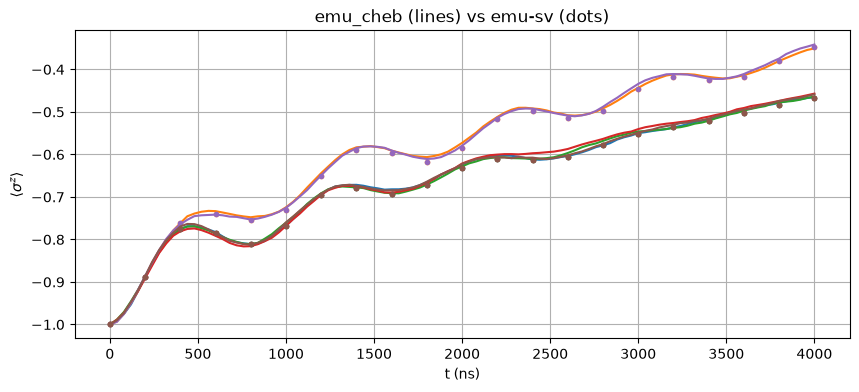

In [7]:
t0 = time.perf_counter()
sv_results = emu_sv.SVBackend(seq, config=emu_sv.SVConfig(dt=dt, observables=[emu_sv.Occupation(evaluation_times=eval_times)], noise_model=noise_model, gpu=False)).run()
t_sv = time.perf_counter() - t0
sv_occ = np.array(sv_results.occupation)
diff = np.abs(occupation_values - sv_occ).max()
err = (sim.raw.occupations.std(0) / np.sqrt(n_traj)).numpy()  # standard error, per time and atom
z = np.abs(occupation_values - sv_occ) / np.maximum(err, 1e-12)
print(f"max |<n_i> emu_cheb - emu-sv| = {diff:.4f} (standard error up to {err.max():.4f}; max z = {z[1:].max():.1f})")
print(f"time: emu_cheb {t_cheb:.2f} s, emu-sv {t_sv:.2f} s (CPU unless a GPU is available)")

plt.figure(figsize=(10, 4))
for i in range(2 * N):
    (line,) = plt.plot(times, 2 * occupation_values[:, i] - 1, label=f"atom {i}")
    plt.plot(times[::5], 2 * sv_occ[::5, i] - 1, "o", color=line.get_color(), ms=3)
plt.title("emu_cheb (lines) vs emu-sv (dots)")
plt.xlabel("t (ns)")
plt.ylabel(r"$\langle \sigma^z \rangle$")
plt.grid()
plt.show()